# 10. Sequential Deep Learning: RNN, LSTM, GRU and Transformers

**Deep Learning with TensorFlow | Beginner to Intermediate**

This notebook introduces neural networks for sequential data. We begin with recurrent neural networks (RNNs), study the limitations of simple recurrence, and then examine Long Short-Term Memory (LSTM) and Gated Recurrent Unit (GRU) networks. We finish with attention and an encoder-only Transformer for multi-step time-series forecasting.

**Practical project:** forecast the next 12 observations of a synthetic, multi-frequency signal from a 48-step historical window. The dataset is generated locally with NumPy; no external download is required.

> **Important:** the signal is synthetic and is intended to teach sequence modeling. It is not a biological or clinical dataset, and the resulting models are not medical predictors.

**Notebook map:** sequence representations → temporal splitting and windowing → RNN → LSTM and GRU → attention → Transformer → model comparison and error analysis.

## Learning objectives

By the end of this notebook, you should be able to:

1. Explain what makes data sequential and distinguish sequence-to-one, sequence-to-sequence, and multi-step forecasting tasks.
2. Represent sequential data with tensors of shape `(batch, time, features)`.
3. Describe recurrent hidden states and the vanishing/exploding gradient problem.
4. Explain the roles of the input, forget, and output gates in an LSTM and the update/reset gates in a GRU.
5. Build and compare SimpleRNN, LSTM, and GRU models with Keras.
6. Explain queries, keys, values, scaled dot-product attention, and multi-head attention.
7. Implement sinusoidal positional encodings and construct a Transformer encoder block.
8. Split and scale time-series data without leaking future information.
9. Evaluate multi-step forecasts with MAE and RMSE and inspect forecast errors.

## 1. What is sequential data?

A sequence is an ordered collection of observations. Unlike an ordinary tabular dataset, the order of the observations carries information. Examples include:

- sensor measurements recorded over time;
- daily financial or environmental measurements;
- physiological signals such as ECG traces;
- longitudinal laboratory measurements;
- text, audio, and event sequences.

Let a sequence contain $T$ time steps. At each time step $t$, the input may contain $F$ features:

$$
X = (x_1, x_2, \ldots, x_T), \qquad x_t \in \mathbb{R}^{F}
$$

A common batched representation is:

$$
\text{shape}(X) = (B, T, F)
$$

where $B$ is the batch size, $T$ is the sequence length, and $F$ is the number of features per time step.

### Common sequential prediction tasks

| Task | Input | Output | Example |
|---|---|---|---|
| Sequence-to-one | A sequence | One value or label | Classify an ECG segment |
| Sequence-to-sequence | A sequence | An output at each time step | Label each time point |
| Multi-step forecasting | A historical window | Several future values | Forecast the next 12 measurements |
| Autoregressive generation | Previous tokens/values | The next token/value, repeatedly | Language or signal generation |

This notebook focuses on **multi-step forecasting**. A historical window of length $L$ is mapped directly to a future horizon of length $H$:

$$
(x_{t-L+1}, \ldots, x_t) \longrightarrow (y_{t+1}, \ldots, y_{t+H})
$$

The models therefore produce all $H$ future values in one forward pass. This is called *direct multi-horizon forecasting*; it is different from predicting one step and feeding that prediction back repeatedly.

## 2. Imports, reproducibility, and runtime

We use TensorFlow/Keras for neural networks, NumPy for data generation and mathematical demonstrations, Matplotlib for plots, and scikit-learn for evaluation metrics.

In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Keras:", getattr(keras, "__version__", "tf.keras"))
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
Keras: 3.15.1
Available GPUs: []


## 3. Create a synthetic time series

We create one continuous signal from multiple sinusoidal components, a small trend, and random measurement noise. The different frequencies make the sequence more informative than a single regular sine wave.

The model will observe the previous 48 values and forecast the next 12 values. We use one feature per time step in this introductory project; the same tensor convention extends to multivariate sequences with $F > 1$.

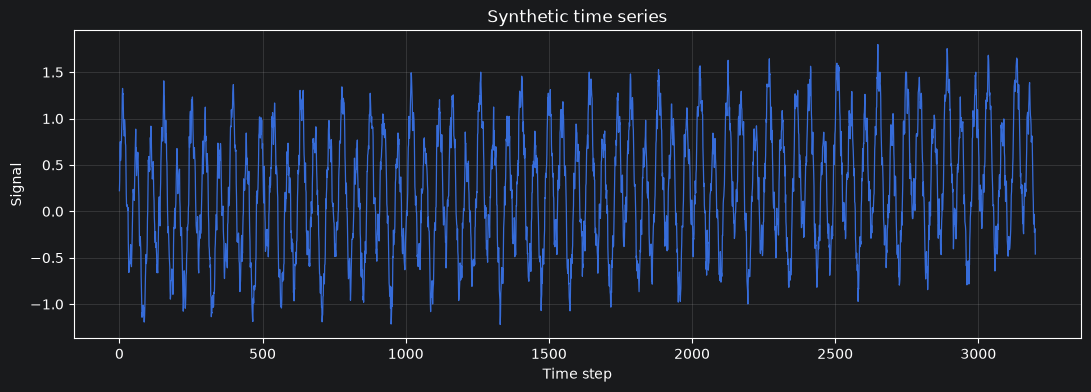

In [2]:
N_STEPS = 3200
rng = np.random.default_rng(SEED)
time = np.arange(N_STEPS, dtype=np.float32)

seasonal_1 = 0.80 * np.sin(2.0 * np.pi * time / 48.0)
seasonal_2 = 0.35 * np.sin(2.0 * np.pi * time / 125.0 + 0.6)
seasonal_3 = 0.15 * np.sin(2.0 * np.pi * time / 9.0)
trend = 0.00015 * time
noise = rng.normal(0.0, 0.08, size=N_STEPS)
series = (seasonal_1 + seasonal_2 + seasonal_3 + trend + noise).astype(np.float32)

plt.figure(figsize=(13, 4))
plt.plot(time, series, linewidth=0.9)
plt.title("Synthetic time series")
plt.xlabel("Time step")
plt.ylabel("Signal")
plt.grid(alpha=0.25)
plt.show()

### Inspect the components

Plotting the components separately helps explain why a model may need to learn patterns at more than one temporal scale.

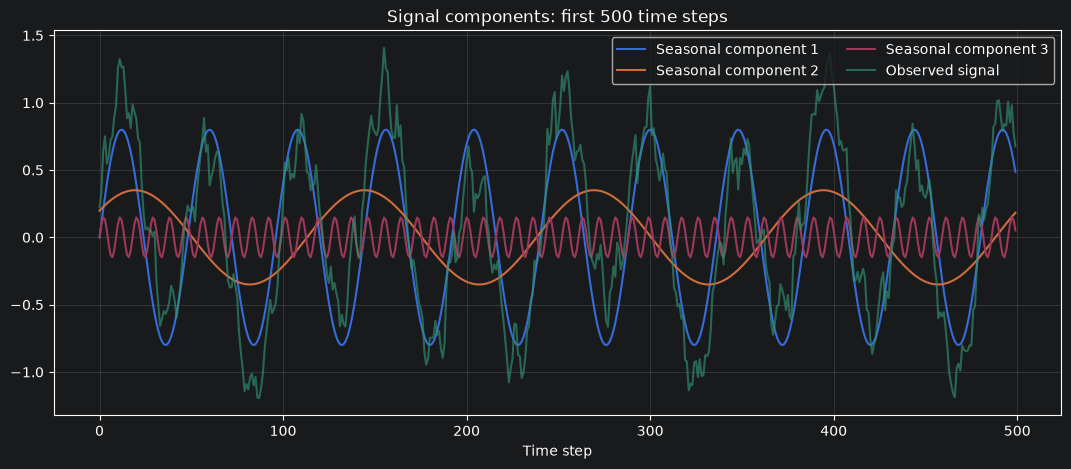

In [3]:
plt.figure(figsize=(13, 5))
plt.plot(time[:500], seasonal_1[:500], label="Seasonal component 1")
plt.plot(time[:500], seasonal_2[:500], label="Seasonal component 2")
plt.plot(time[:500], seasonal_3[:500], label="Seasonal component 3")
plt.plot(time[:500], series[:500], label="Observed signal", alpha=0.65)
plt.title("Signal components: first 500 time steps")
plt.xlabel("Time step")
plt.legend(ncol=2)
plt.grid(alpha=0.25)
plt.show()

## 4. Chronological splitting and leakage-safe scaling

For sequential forecasting, randomly splitting overlapping windows can place near-identical time points in both training and test sets. It can also allow the model to learn from future observations when estimating preprocessing statistics.

We therefore:

1. divide the raw timeline chronologically into training, validation, and test periods;
2. estimate the mean and standard deviation from the **training period only**;
3. transform the full series using those training statistics;
4. construct windows whose target horizon belongs entirely to one split.

The first validation window may use the final training observations as historical context. Likewise, the first test window may use prior validation observations as context. This is realistic for rolling forecasts: past observations are available when predicting a future period. No validation or test target is used to fit the scaler.

In [4]:
SEQ_LEN = 48
HORIZON = 12
N_FEATURES = 1

train_end = int(N_STEPS * 0.70)
val_end = int(N_STEPS * 0.85)

train_mean = float(series[:train_end].mean())
train_std = float(series[:train_end].std())
if train_std == 0:
    raise ValueError("Training standard deviation is zero; scaling is undefined.")

series_scaled = (series - train_mean) / train_std
print("Raw split boundaries:", 0, train_end, val_end, N_STEPS)
print("Training-only mean and std:", train_mean, train_std)

Raw split boundaries: 0 2240 2720 3200
Training-only mean and std: 0.16781337559223175 0.6351372599601746


### Build sliding windows

For a start index $s$, the input is $x_{s:s+L}$ and the target is $x_{s+L:s+L+H}$. The target end index is exclusive. Each window is assigned according to the time interval containing its target values.

In [5]:
all_starts = np.arange(0, N_STEPS - SEQ_LEN - HORIZON + 1, dtype=np.int32)
target_starts = all_starts + SEQ_LEN
target_ends = target_starts + HORIZON

train_starts = all_starts[target_ends <= train_end]
val_starts = all_starts[(target_starts >= train_end) & (target_ends <= val_end)]
test_starts = all_starts[(target_starts >= val_end) & (target_ends <= N_STEPS)]


def make_windows(values, starts, sequence_length=SEQ_LEN, horizon=HORIZON):
    """Return X: (samples, sequence_length, 1), y: (samples, horizon)."""
    X = np.stack([values[s:s + sequence_length] for s in starts]).astype(np.float32)
    y = np.stack([values[s + sequence_length:s + sequence_length + horizon] for s in starts]).astype(np.float32)
    return X[..., np.newaxis], y


X_train, y_train = make_windows(series_scaled, train_starts)
X_val, y_val = make_windows(series_scaled, val_starts)
X_test, y_test = make_windows(series_scaled, test_starts)

print("X_train, y_train:", X_train.shape, y_train.shape)
print("X_val, y_val:", X_val.shape, y_val.shape)
print("X_test, y_test:", X_test.shape, y_test.shape)

X_train, y_train: (2181, 48, 1) (2181, 12)
X_val, y_val: (469, 48, 1) (469, 12)
X_test, y_test: (469, 48, 1) (469, 12)


### Check one input-target pair

The input window ends immediately before the first target value. The target horizon contains 12 consecutive future observations.

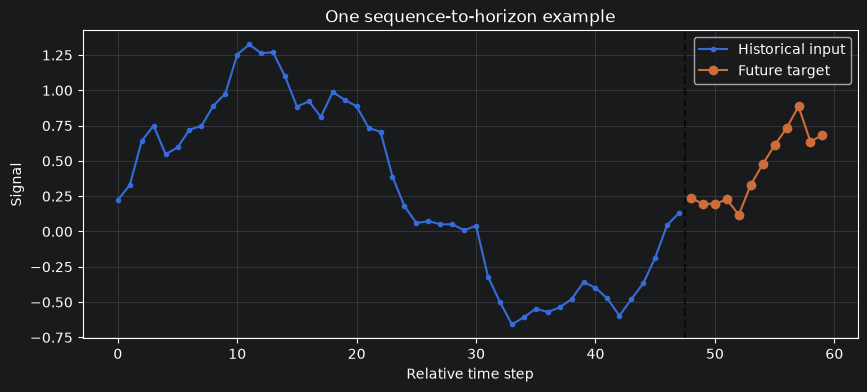

In [6]:
example_index = 0
example_input = X_train[example_index, :, 0] * train_std + train_mean
example_target = y_train[example_index] * train_std + train_mean

plt.figure(figsize=(10, 4))
input_times = np.arange(SEQ_LEN)
target_times = np.arange(SEQ_LEN, SEQ_LEN + HORIZON)
plt.plot(input_times, example_input, marker=".", label="Historical input")
plt.plot(target_times, example_target, marker="o", label="Future target")
plt.axvline(SEQ_LEN - 0.5, color="black", linestyle="--", alpha=0.6)
plt.title("One sequence-to-horizon example")
plt.xlabel("Relative time step")
plt.ylabel("Signal")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### Tensor shape recap

A recurrent or Transformer model typically receives a rank-3 input tensor:

$$
X \in \mathbb{R}^{B\times T\times F}
$$

For this project, each sample has 48 time steps and one feature. The batch dimension is variable and is not fixed in the model input specification.

In [7]:
print("One sample:", X_train[0].shape)
print("One batch:", X_train[:32].shape)
print("Targets in one batch:", y_train[:32].shape)

One sample: (48, 1)
One batch: (32, 48, 1)
Targets in one batch: (32, 12)


## 5. Recurrent Neural Networks (RNNs)

A recurrent neural network processes a sequence one time step at a time. It maintains a hidden state that summarizes information from the previous steps.

A simple RNN can be written as:

$$
h_t = \phi(W_x x_t + W_h h_{t-1} + b_h)
$$

$$
\hat{y}_t = W_y h_t + b_y
$$

where $x_t$ is the current input, $h_{t-1}$ is the previous hidden state, $W_x$ and $W_h$ are learned weight matrices, and $\phi$ is often a `tanh` activation.

The same recurrent weights are reused at every time step. This parameter sharing allows an RNN to process sequences of different lengths, subject to the input and model design.

### How the hidden state is updated

The state is a learned summary, not a complete copy of the past. At each step, the network combines the current input with the previous state. Information that is useful for the task must survive repeated state updates.

In [8]:
# A tiny NumPy illustration of repeated hidden-state updates (not a trainable model).
sequence_example = np.array([0.2, -0.1, 0.5, 0.3], dtype=np.float32)
hidden = 0.0
hidden_trace = []
for value in sequence_example:
    hidden = np.tanh(0.8 * value + 0.7 * hidden)
    hidden_trace.append(hidden)

print("Input sequence:", sequence_example)
print("Hidden-state trace:", np.round(hidden_trace, 4))

Input sequence: [ 0.2 -0.1  0.5  0.3]
Hidden-state trace: [0.1586 0.031  0.3984 0.4768]


### `return_sequences` and output shapes

In Keras, `return_sequences=False` (the default) returns only the final output/state from the recurrent layer. With `return_sequences=True`, the layer returns an output at every time step.

- Use the final output for sequence-to-one tasks or when a Dense head predicts a fixed future horizon from the complete historical window.
- Use `return_sequences=True` when stacking recurrent layers or predicting at every time step.

In [9]:
# Shape demonstration. These layers are defined but not trained.
shape_input = keras.Input(shape=(SEQ_LEN, N_FEATURES))
last_state = layers.SimpleRNN(16, return_sequences=False)(shape_input)
all_states = layers.SimpleRNN(16, return_sequences=True)(shape_input)
shape_model_last = keras.Model(shape_input, last_state)
shape_model_all = keras.Model(shape_input, all_states)

print("Final state shape:", shape_model_last.output_shape)
print("Full sequence shape:", shape_model_all.output_shape)

Final state shape: (None, 16)
Full sequence shape: (None, 48, 16)


## 6. Vanishing and exploding gradients

Training a recurrent network requires gradients to pass backward through many time steps. Repeated multiplication by Jacobian terms can make the gradient shrink or grow rapidly.

A simplified scalar illustration is:

$$
\frac{\partial h_T}{\partial h_0} \approx \prod_{t=1}^{T} a_t
$$

If the magnitudes of the factors are consistently below one, the product tends toward zero (vanishing gradients). If they are consistently above one, the product can grow very large (exploding gradients). Real RNNs involve matrices and nonlinearities, but this product captures the basic intuition.

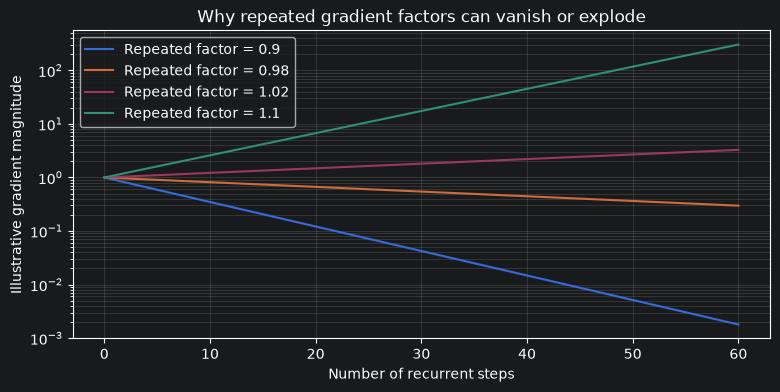

In [10]:
steps = np.arange(0, 61)
plt.figure(figsize=(9, 4))
for factor in [0.90, 0.98, 1.02, 1.10]:
    plt.plot(steps, np.power(factor, steps), label=f"Repeated factor = {factor}")
plt.yscale("log")
plt.xlabel("Number of recurrent steps")
plt.ylabel("Illustrative gradient magnitude")
plt.title("Why repeated gradient factors can vanish or explode")
plt.legend()
plt.grid(alpha=0.25, which="both")
plt.show()

### Practical consequences

- A simple RNN may struggle to preserve information across long intervals.
- Exploding gradients can make optimization unstable; gradient clipping can help.
- Gated architectures such as LSTM and GRU provide controlled paths for information flow.
- Gating improves the ability to learn longer dependencies, but it does not guarantee that every long-range dependency will be learned.

## 7. Long Short-Term Memory (LSTM)

An LSTM maintains a hidden state $h_t$ and a cell state $c_t$. Its gates regulate which information is forgotten, added, and exposed.

A common LSTM formulation is:

$$
f_t = \sigma(W_f x_t + U_f h_{t-1} + b_f)
$$

$$
i_t = \sigma(W_i x_t + U_i h_{t-1} + b_i), \qquad
\tilde{c}_t = \tanh(W_c x_t + U_c h_{t-1} + b_c)
$$

$$
c_t = f_t \odot c_{t-1} + i_t \odot \tilde{c}_t
$$

$$
o_t = \sigma(W_o x_t + U_o h_{t-1} + b_o), \qquad
h_t = o_t \odot \tanh(c_t)
$$

Here, $\sigma$ is the sigmoid function and $\odot$ denotes element-wise multiplication.

### LSTM gate intuition

| Component | Main role | Typical question |
|---|---|---|
| Forget gate $f_t$ | Controls retention of previous cell state | What should be kept? |
| Input gate $i_t$ | Controls how much candidate information is written | What new information should be added? |
| Candidate $\tilde{c}_t$ | Creates candidate cell content | What could be stored? |
| Output gate $o_t$ | Controls what part of the cell state becomes hidden output | What should be exposed now? |

The cell state provides a path through which information can be retained over multiple steps. The gates learn their behavior from data; they are not manually assigned semantic meanings by the user.

### Build an LSTM model

Keras `LSTM` accepts a 3D input with shape `(batch, timesteps, features)`. We use the final sequence representation and a Dense layer to predict the 12 future values.

In [11]:
def build_lstm_model():
    inputs = keras.Input(shape=(SEQ_LEN, N_FEATURES), name="historical_window")
    x = layers.LSTM(48, name="lstm_encoder")(inputs)
    x = layers.Dropout(0.10)(x)
    outputs = layers.Dense(HORIZON, name="future_horizon")(x)
    model = keras.Model(inputs, outputs, name="lstm_forecaster")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="mse",
        metrics=[keras.metrics.MeanAbsoluteError(name="mae")],
    )
    return model

lstm_model = build_lstm_model()
lstm_model.summary()

Model: "lstm_forecaster"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ historical_window (InputLayer)  │ (None, 48, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_encoder (LSTM)             │ (None, 48)             │         9,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 48)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ future_horizon (Dense)          │ (None, 12)             │           588 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,188 (39.80 KB)

 Trainable params: 10,188 (39.80 KB)

 Non-trainable params: 0 (0.00 B)

## 8. Gated Recurrent Unit (GRU)

A GRU is another gated recurrent architecture. It combines information-control mechanisms into an update gate and a reset gate and does not maintain a separate LSTM-style cell state.

One common GRU convention is:

$$
z_t = \sigma(W_z x_t + U_z h_{t-1})
$$

$$
r_t = \sigma(W_r x_t + U_r h_{t-1})
$$

$$
\tilde{h}_t = \tanh(W_h x_t + U_h(r_t \odot h_{t-1}))
$$

$$
h_t = (1-z_t)\odot h_{t-1} + z_t\odot\tilde{h}_t
$$

Different implementations and references may use the complementary convention for the update gate. The exact gate convention should therefore be checked when comparing equations across sources.

### GRU gate intuition

- **Reset gate:** controls how much of the previous hidden state contributes to the candidate state.
- **Update gate:** controls the mixture of the previous state and the candidate state.

GRUs have a simpler state structure than LSTMs. Neither architecture is universally better; performance depends on the dataset, sequence length, model size, and optimization setup.

In [12]:
def build_gru_model():
    inputs = keras.Input(shape=(SEQ_LEN, N_FEATURES), name="historical_window")
    x = layers.GRU(48, name="gru_encoder")(inputs)
    x = layers.Dropout(0.10)(x)
    outputs = layers.Dense(HORIZON, name="future_horizon")(x)
    model = keras.Model(inputs, outputs, name="gru_forecaster")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="mse",
        metrics=[keras.metrics.MeanAbsoluteError(name="mae")],
    )
    return model

gru_model = build_gru_model()
gru_model.summary()

Model: "gru_forecaster"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ historical_window (InputLayer)  │ (None, 48, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_encoder (GRU)               │ (None, 48)             │         7,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 48)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ future_horizon (Dense)          │ (None, 12)             │           588 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,932 (30.98 KB)

 Trainable params: 7,932 (30.98 KB)

 Non-trainable params: 0 (0.00 B)

## 9. SimpleRNN, LSTM, and GRU: comparison

| Model | State design | Main strength | Common limitation |
|---|---|---|---|
| SimpleRNN | One hidden state | Simple baseline; few parameters | Often struggles with long dependencies |
| LSTM | Hidden state + cell state + three gates | Explicit cell-state pathway | More gates and parameters |
| GRU | Hidden state + two gates | Simpler gated alternative | May behave differently from LSTM on long or complex sequences |

A fair experiment should keep the data split, input window, forecast horizon, and evaluation protocol constant. It should also record model size and runtime, not only forecast error.

In [13]:
def build_simple_rnn_model():
    inputs = keras.Input(shape=(SEQ_LEN, N_FEATURES), name="historical_window")
    x = layers.SimpleRNN(48, name="simple_rnn_encoder")(inputs)
    x = layers.Dropout(0.10)(x)
    outputs = layers.Dense(HORIZON, name="future_horizon")(x)
    model = keras.Model(inputs, outputs, name="simple_rnn_forecaster")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="mse",
        metrics=[keras.metrics.MeanAbsoluteError(name="mae")],
    )
    return model

simple_rnn_model = build_simple_rnn_model()
simple_rnn_model.summary()

Model: "simple_rnn_forecaster"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ historical_window (InputLayer)  │ (None, 48, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_encoder (SimpleRNN)  │ (None, 48)             │         2,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 48)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ future_horizon (Dense)          │ (None, 12)             │           588 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,988 (11.67 KB)

 Trainable params: 2,988 (11.67 KB)

 Non-trainable params: 0 (0.00 B)

### Bidirectional recurrent layers

A bidirectional RNN processes an input window in both forward and backward directions and combines the two representations. This can be useful when the **entire input sequence is already observed** and the task is to encode that completed window.

For forecasting, a bidirectional encoder over a historical window does not automatically leak future targets: all positions in that window occur before the forecast origin. However, a bidirectional model is generally not appropriate when generating a sequence autoregressively one position at a time, because a representation at an earlier position can incorporate later positions from the same sequence.

In [14]:
# Optional shape demonstration for a bidirectional LSTM encoder.
bi_input = keras.Input(shape=(SEQ_LEN, N_FEATURES))
bi_output = layers.Bidirectional(layers.LSTM(16))(bi_input)
bi_model = keras.Model(bi_input, bi_output)
print("Bidirectional final representation:", bi_model.output_shape)

Bidirectional final representation: (None, 32)


## 10. Prepare efficient TensorFlow datasets

We shuffle only the training windows. Validation and test windows remain in chronological order. Prefetching can overlap data preparation with model execution.

In [15]:
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(buffer_size=min(len(X_train), 2048), seed=SEED, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH_SIZE).prefetch(AUTOTUNE)
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(BATCH_SIZE).prefetch(AUTOTUNE)

for batch_X, batch_y in train_ds.take(1):
    print("Batch input:", batch_X.shape)
    print("Batch target:", batch_y.shape)

Batch input: (32, 48, 1)
Batch target: (32, 12)


## 11. Train recurrent models

We compare a SimpleRNN, LSTM, and GRU under the same training budget. Early stopping restores the weights from the epoch with the lowest validation loss. For a larger experiment, increase the epoch budget and repeat training with multiple random seeds.

In [16]:
EPOCHS = 20


def train_model(model, train_data=train_ds, validation_data=val_ds, epochs=EPOCHS):
    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=4, restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5
        ),
    ]
    history = model.fit(
        train_data,
        validation_data=validation_data,
        epochs=epochs,
        callbacks=callbacks,
        verbose=1,
    )
    return history

histories = {}
recurrent_models = {
    "SimpleRNN": build_simple_rnn_model(),
    "LSTM": build_lstm_model(),
    "GRU": build_gru_model(),
}

for model_name, model in recurrent_models.items():
    print(f"\nTraining {model_name}")
    histories[model_name] = train_model(model)


Training SimpleRNN
Epoch 1/20


G:\CancerAI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


69/69 ━━━━━━━━━━━━━━━━━━━━ 14s 71ms/step - loss: 0.5212 - mae: 0.5583 - val_loss: 0.2213 - val_mae: 0.3648 - learning_rate: 0.0010
Epoch 2/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.1740 - mae: 0.3301 - val_loss: 0.1485 - val_mae: 0.3032 - learning_rate: 0.0010
Epoch 3/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.1408 - mae: 0.2987 - val_loss: 0.1375 - val_mae: 0.2914 - learning_rate: 0.0010
Epoch 4/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.1220 - mae: 0.2782 - val_loss: 0.1190 - val_mae: 0.2724 - learning_rate: 0.0010
Epoch 5/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1146 - mae: 0.2680 - val_loss: 0.1201 - val_mae: 0.2719 - learning_rate: 0.0010
Epoch 6/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.1176 - mae: 0.2727 - val_loss: 0.1125 - val_mae: 0.2646 - learning_rate: 0.0010
Epoch 7/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0973 - mae: 0.2468 - val_loss: 0.1197 - val_mae: 0.2722 - learning_rate: 0.0010
Epoch 8/20
69/69 ━━━━━━━━━━━

### Plot recurrent-model learning curves

Training loss indicates fit to the training windows. Validation loss is the more relevant signal for model selection. A widening gap can indicate overfitting; both curves remaining high can indicate underfitting or an optimization problem.

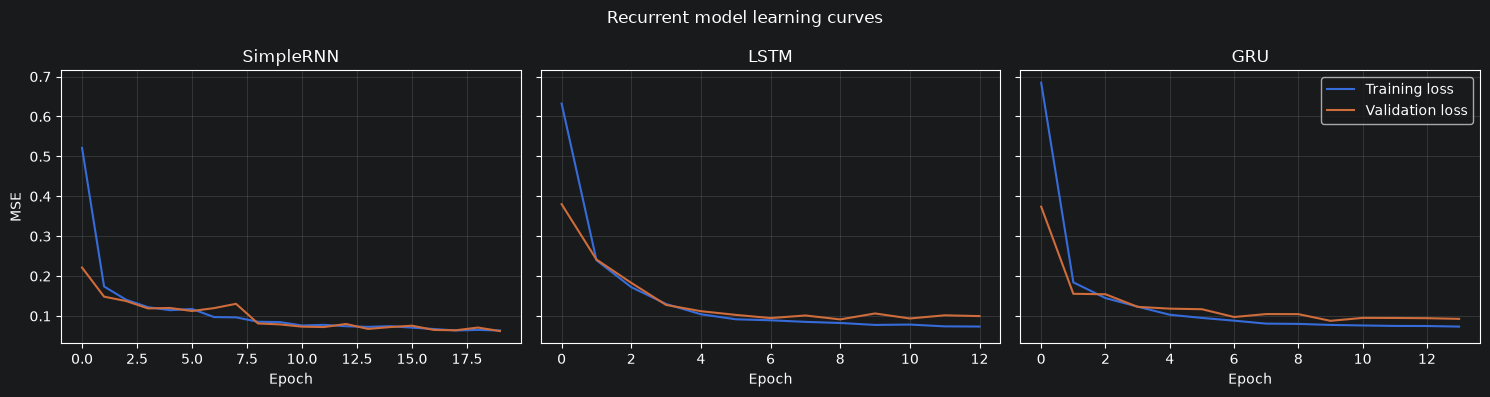

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (name, history) in zip(axes, histories.items()):
    ax.plot(history.history["loss"], label="Training loss")
    ax.plot(history.history["val_loss"], label="Validation loss")
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("MSE")
axes[-1].legend()
plt.suptitle("Recurrent model learning curves")
plt.tight_layout()
plt.show()

## 12. Attention mechanism

Attention allows a model to form a context-dependent representation by weighting information from different positions. In self-attention, the queries, keys, and values are all derived from the same input sequence.

For a sequence representation matrix $X$, learned projections create:

$$
Q = XW_Q, \qquad K = XW_K, \qquad V = XW_V
$$

- **Query:** what a position is looking for;
- **Key:** what each position makes available for matching;
- **Value:** the content aggregated when a position is attended to.

These labels are useful intuition. Queries, keys, and values are learned vectors, not manually assigned meanings.

### Scaled dot-product attention

The attention weights are computed from query-key similarity scores:

$$
\operatorname{Attention}(Q,K,V) =
\operatorname{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}\right)V
$$

The scale factor $\sqrt{d_k}$ helps keep dot-product magnitudes from becoming too large as the key dimension grows. The softmax is applied across key positions so that the weights for each query position sum to one.

### A small NumPy attention example

The next cell demonstrates the operations for one query and a short sequence. It is a mathematical illustration, not a trainable neural-network layer.

In [18]:
def softmax_np(values, axis=-1):
    shifted = values - np.max(values, axis=axis, keepdims=True)
    exp_values = np.exp(shifted)
    return exp_values / np.sum(exp_values, axis=axis, keepdims=True)

rng_attention = np.random.default_rng(SEED)
sequence_length_demo = 5
key_dim_demo = 4
value_dim_demo = 3
Q_demo = rng_attention.normal(size=(1, key_dim_demo))
K_demo = rng_attention.normal(size=(sequence_length_demo, key_dim_demo))
V_demo = rng_attention.normal(size=(sequence_length_demo, value_dim_demo))

scores_demo = (Q_demo @ K_demo.T) / np.sqrt(key_dim_demo)
weights_demo = softmax_np(scores_demo, axis=-1)
context_demo = weights_demo @ V_demo

print("Attention weights:", np.round(weights_demo, 3))
print("Weights sum:", float(weights_demo.sum()))
print("Context vector:", np.round(context_demo, 3))

Attention weights: [[0.142 0.336 0.048 0.255 0.219]]
Weights sum: 1.0
Context vector: [[-0.067  0.041  0.302]]


## 13. Multi-head attention

Multi-head attention applies multiple attention projections in parallel. Each head can learn a different set of relationships among sequence positions. The head outputs are concatenated and projected to the model dimension.

Conceptually:

$$
\operatorname{head}_i = \operatorname{Attention}(QW_i^Q, KW_i^K, VW_i^V)
$$

$$
\operatorname{MHA}(Q,K,V) =
\operatorname{Concat}(\operatorname{head}_1,\ldots,\operatorname{head}_h)W^O
$$

In Keras, `layers.MultiHeadAttention` performs the projections and attention computation. Its `key_dim` argument is the dimension **per head**, not the total model dimension.

## 14. Positional encoding

Self-attention alone does not encode sequence order. If the same set of vectors is permuted, standard self-attention without positional information has no built-in indication of the original positions.

The original Transformer introduced sinusoidal positional encodings:

$$
PE_{(pos,2i)} = \sin\left(\frac{pos}{10000^{2i/d_{model}}}\right)
$$

$$
PE_{(pos,2i+1)} = \cos\left(\frac{pos}{10000^{2i/d_{model}}}\right)
$$

The positional encoding is added to the input representation. Learned position embeddings are another common option.

In [19]:
def sinusoidal_positional_encoding(seq_len, d_model):
    positions = np.arange(seq_len, dtype=np.float32)[:, np.newaxis]
    dimensions = np.arange(d_model, dtype=np.float32)[np.newaxis, :]
    angle_rates = 1.0 / np.power(10000.0, (2.0 * np.floor(dimensions / 2.0)) / d_model)
    angles = positions * angle_rates
    encoding = np.zeros((seq_len, d_model), dtype=np.float32)
    encoding[:, 0::2] = np.sin(angles[:, 0::2])
    encoding[:, 1::2] = np.cos(angles[:, 1::2])
    return encoding

POS_DEMO = sinusoidal_positional_encoding(seq_len=64, d_model=32)
print("Positional encoding shape:", POS_DEMO.shape)

Positional encoding shape: (64, 32)


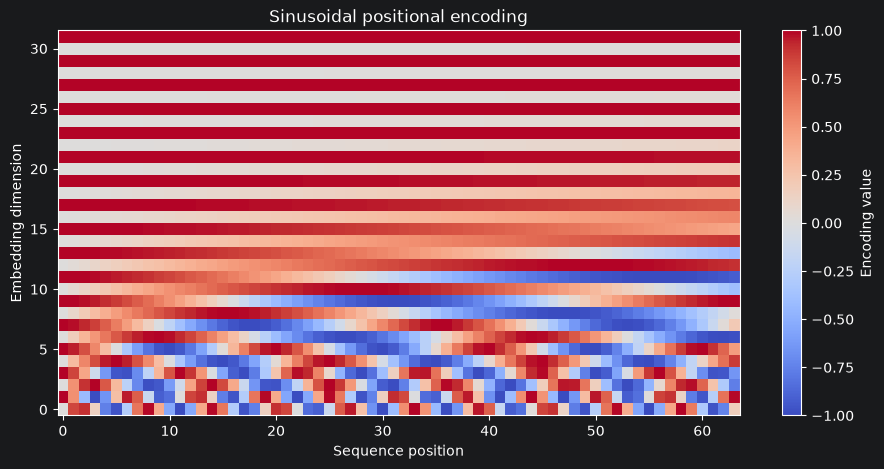

In [20]:
plt.figure(figsize=(11, 5))
plt.imshow(POS_DEMO.T, aspect="auto", origin="lower", cmap="coolwarm")
plt.colorbar(label="Encoding value")
plt.xlabel("Sequence position")
plt.ylabel("Embedding dimension")
plt.title("Sinusoidal positional encoding")
plt.show()

## 15. Transformer encoder architecture

A Transformer encoder block commonly contains:

1. multi-head self-attention;
2. a residual connection and layer normalization;
3. a position-wise feed-forward network;
4. another residual connection and layer normalization.

A stack of these blocks can process the complete input window. In contrast to an RNN, self-attention does not need to update a single recurrent state step by step; positions within a window can be processed in parallel.

For a sequence of length $T$, full self-attention forms pairwise interactions across positions, giving a time and attention-matrix cost that grows quadratically with $T$ (approximately $O(T^2)$ with respect to sequence length, ignoring feature-dimension factors). This can become expensive for very long sequences.

### Encoder-only Transformer for forecasting

Our input contains only historical observations up to the forecast origin. We encode this observed window with self-attention, pool the sequence representation, and map it to the next 12 values.

Because no future target positions are present in the input, this encoder-only forecasting setup does **not** require a causal mask to prevent the model from seeing future targets. A causal mask is important for autoregressive decoding or next-token prediction, where a position must not attend to later target positions.

In [21]:
D_MODEL = 32
NUM_HEADS = 4
FF_DIM = 64
DROPOUT_RATE = 0.10


class AddSinusoidalPositionEncoding(layers.Layer):
    """Add a fixed sinusoidal position encoding to (batch, time, channels)."""
    def __init__(self, sequence_length, d_model, **kwargs):
        super().__init__(**kwargs)
        self.sequence_length = int(sequence_length)
        self.d_model = int(d_model)
        encoding = sinusoidal_positional_encoding(self.sequence_length, self.d_model)
        self.encoding = tf.constant(encoding[np.newaxis, ...], dtype=tf.float32)

    def call(self, inputs):
        return inputs + tf.cast(self.encoding, dtype=inputs.dtype)

    def get_config(self):
        config = super().get_config()
        config.update({"sequence_length": self.sequence_length, "d_model": self.d_model})
        return config


class TransformerEncoderBlock(layers.Layer):
    def __init__(self, embed_dim, num_heads, ff_dim, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        if embed_dim % num_heads != 0:
            raise ValueError("embed_dim must be divisible by num_heads")
        self.embed_dim = int(embed_dim)
        self.num_heads = int(num_heads)
        self.ff_dim = int(ff_dim)
        self.dropout_rate = float(dropout_rate)
        self.attention = layers.MultiHeadAttention(
            num_heads=self.num_heads,
            key_dim=self.embed_dim // self.num_heads,
            dropout=self.dropout_rate,
            name="self_attention",
        )
        self.ffn = keras.Sequential(
            [
                layers.Dense(self.ff_dim, activation="gelu"),
                layers.Dense(self.embed_dim),
            ],
            name="feed_forward",
        )
        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = layers.LayerNormalization(epsilon=1e-6)
        self.dropout1 = layers.Dropout(self.dropout_rate)
        self.dropout2 = layers.Dropout(self.dropout_rate)

    def call(self, inputs, training=None):
        attention_output = self.attention(
            query=inputs, key=inputs, value=inputs, training=training
        )
        x = self.norm1(inputs + self.dropout1(attention_output, training=training))
        ffn_output = self.ffn(x, training=training)
        return self.norm2(x + self.dropout2(ffn_output, training=training))

    def get_config(self):
        config = super().get_config()
        config.update({
            "embed_dim": self.embed_dim,
            "num_heads": self.num_heads,
            "ff_dim": self.ff_dim,
            "dropout_rate": self.dropout_rate,
        })
        return config

### Build the Transformer forecaster

A Dense layer first projects the one-dimensional input into a `D_MODEL`-dimensional representation. We then add positional information, apply an encoder block, pool across time, and predict the fixed forecast horizon.

In [22]:
def build_transformer_model():
    inputs = keras.Input(shape=(SEQ_LEN, N_FEATURES), name="historical_window")
    x = layers.Dense(D_MODEL, name="input_projection")(inputs)
    x = AddSinusoidalPositionEncoding(SEQ_LEN, D_MODEL, name="position_encoding")(x)
    x = TransformerEncoderBlock(
        embed_dim=D_MODEL,
        num_heads=NUM_HEADS,
        ff_dim=FF_DIM,
        dropout_rate=DROPOUT_RATE,
        name="transformer_encoder",
    )(x)
    x = layers.GlobalAveragePooling1D(name="temporal_pooling")(x)
    x = layers.Dropout(DROPOUT_RATE)(x)
    outputs = layers.Dense(HORIZON, name="future_horizon")(x)
    model = keras.Model(inputs, outputs, name="transformer_forecaster")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="mse",
        metrics=[keras.metrics.MeanAbsoluteError(name="mae")],
    )
    return model

transformer_model = build_transformer_model()
transformer_model.summary()

Model: "transformer_forecaster"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ historical_window (InputLayer)  │ (None, 48, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ input_projection (Dense)        │ (None, 48, 32)         │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ position_encoding               │ (None, 48, 32)         │             0 │
│ (AddSinusoidalPositionEncoding) │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_encoder             │ (None, 48, 32)         │         8,544 │
│ (TransformerEncoderBlock)       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ temporal_pooling                │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ future_horizon (Dense)          │ (None, 12)             │           396 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,004 (35.17 KB)

 Trainable params: 9,004 (35.17 KB)

 Non-trainable params: 0 (0.00 B)

### Inspect attention scores

Keras `MultiHeadAttention` can optionally return the attention scores as well as the attention output. The score tensor has shape `(batch, heads, query_length, key_length)` for this 1D self-attention example.

In [23]:
attention_demo = layers.MultiHeadAttention(num_heads=NUM_HEADS, key_dim=D_MODEL // NUM_HEADS)
demo_input = tf.random.normal((1, SEQ_LEN, D_MODEL), seed=SEED)
demo_output, demo_scores = attention_demo(
    query=demo_input,
    key=demo_input,
    value=demo_input,
    return_attention_scores=True,
)
print("Attention output:", demo_output.shape)
print("Attention scores:", demo_scores.shape)

Attention output: (1, 48, 32)
Attention scores: (1, 4, 48, 48)


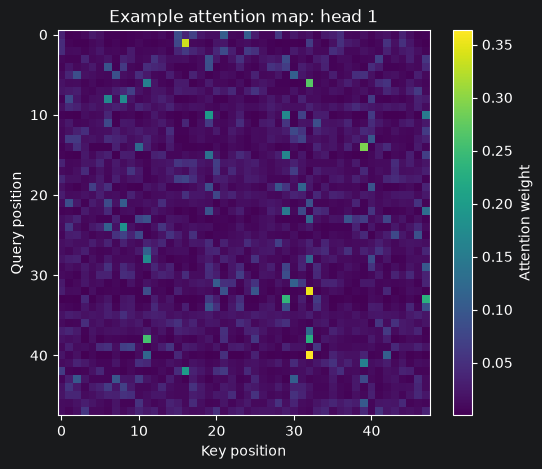

In [24]:
plt.figure(figsize=(6, 5))
plt.imshow(demo_scores.numpy()[0, 0], aspect="auto", cmap="viridis")
plt.colorbar(label="Attention weight")
plt.xlabel("Key position")
plt.ylabel("Query position")
plt.title("Example attention map: head 1")
plt.show()

## 16. Train the Transformer

We use the same training and validation windows, loss, optimizer family, batch size, and callback strategy. The Transformer has a different parameterization and computational profile, so equal epochs do not imply equal training time.

In [25]:
transformer_history = train_model(transformer_model)
histories["Transformer"] = transformer_history

Epoch 1/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - loss: 0.9004 - mae: 0.7761 - val_loss: 0.3986 - val_mae: 0.5153 - learning_rate: 0.0010
Epoch 2/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.2695 - mae: 0.4143 - val_loss: 0.1835 - val_mae: 0.3417 - learning_rate: 0.0010
Epoch 3/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.1466 - mae: 0.3048 - val_loss: 0.1109 - val_mae: 0.2688 - learning_rate: 0.0010
Epoch 4/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.1247 - mae: 0.2809 - val_loss: 0.0910 - val_mae: 0.2433 - learning_rate: 0.0010
Epoch 5/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.1110 - mae: 0.2663 - val_loss: 0.1141 - val_mae: 0.2758 - learning_rate: 0.0010
Epoch 6/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.1066 - mae: 0.2618 - val_loss: 0.0968 - val_mae: 0.2533 - learning_rate: 0.0010
Epoch 7/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.1004 - mae: 0.2541 - val_loss: 0.1355 - val_mae: 0.3036 - learning_rate: 5.0000e-04
Epoch 8/2

## 17. Build a persistence baseline

A neural network should be compared with a simple baseline. The persistence baseline repeats the last observed value across the full forecast horizon:

$$
\hat{y}_{t+h} = y_t, \qquad h=1,\ldots,H
$$

This baseline is intentionally simple. If a neural model cannot outperform it on a held-out period, its additional complexity may not be justified for this dataset.

In [26]:
# Convert standardized targets back to the original signal scale.
y_val_original = y_val * train_std + train_mean
y_test_original = y_test * train_std + train_mean

persistence_val_scaled = np.repeat(X_val[:, -1, 0:1], HORIZON, axis=1)
persistence_val_original = persistence_val_scaled * train_std + train_mean
persistence_scaled = np.repeat(X_test[:, -1, 0:1], HORIZON, axis=1)
persistence_original = persistence_scaled * train_std + train_mean

val_baseline_mae = mean_absolute_error(y_val_original.reshape(-1), persistence_val_original.reshape(-1))
val_baseline_rmse = np.sqrt(mean_squared_error(y_val_original.reshape(-1), persistence_val_original.reshape(-1)))
baseline_mae = mean_absolute_error(y_test_original.reshape(-1), persistence_original.reshape(-1))
baseline_rmse = np.sqrt(mean_squared_error(y_test_original.reshape(-1), persistence_original.reshape(-1)))
print(f"Validation persistence MAE:  {val_baseline_mae:.4f}")
print(f"Test persistence MAE:        {baseline_mae:.4f}")
print(f"Test persistence RMSE:       {baseline_rmse:.4f}")

Validation persistence MAE:  0.4385
Test persistence MAE:        0.4397
Test persistence RMSE:       0.5526


## 18. Select the candidate using validation data

Model selection must be based on the validation period, not the test period. We evaluate each already-trained candidate on validation windows, include the persistence baseline, and select the lowest-validation-MAE neural architecture. The test set remains untouched until the next section.


In [27]:
validation_results = [{
    "Model": "Persistence",
    "Validation_MAE": val_baseline_mae,
    "Validation_RMSE": val_baseline_rmse,
}]
validation_predictions = {"Persistence": persistence_val_original}

for model_name, model in {**recurrent_models, "Transformer": transformer_model}.items():
    prediction_scaled = model.predict(X_val, batch_size=BATCH_SIZE, verbose=0)
    prediction_original = prediction_scaled * train_std + train_mean
    validation_predictions[model_name] = prediction_original
    validation_results.append({
        "Model": model_name,
        "Validation_MAE": mean_absolute_error(y_val_original.reshape(-1), prediction_original.reshape(-1)),
        "Validation_RMSE": np.sqrt(mean_squared_error(y_val_original.reshape(-1), prediction_original.reshape(-1))),
    })

for row in sorted(validation_results, key=lambda row: row["Validation_MAE"]):
    print(f"{row['Model']:>12s} | validation MAE={row['Validation_MAE']:.4f} | validation RMSE={row['Validation_RMSE']:.4f}")

selected_model_name = min(
    [row for row in validation_results if row["Model"] != "Persistence"],
    key=lambda row: row["Validation_MAE"],
)["Model"]
print("\nSelected neural architecture from validation:", selected_model_name)

   SimpleRNN | validation MAE=0.1258 | validation RMSE=0.1584
 Transformer | validation MAE=0.1464 | validation RMSE=0.1804
         GRU | validation MAE=0.1482 | validation RMSE=0.1883
        LSTM | validation MAE=0.1531 | validation RMSE=0.1921
 Persistence | validation MAE=0.4385 | validation RMSE=0.5470

Selected neural architecture from validation: SimpleRNN


## 19. Evaluate all models on the untouched test period

The validation set is used for early stopping. The test set is used only after model training is complete. We report pooled MAE and RMSE over all forecast origins and all horizon positions.

For a more detailed analysis, metrics can also be computed separately for each forecast step. Error often grows with the horizon because farther future values are harder to predict.

The candidate architecture was selected using validation MAE in the previous section. The test results below are a final descriptive comparison; do not use them to revise hyperparameters or select a new model.

In [28]:
all_models = {**recurrent_models, "Transformer": transformer_model}
results = [{
    "Model": "Persistence",
    "MAE": baseline_mae,
    "RMSE": baseline_rmse,
    "Parameters": 0,
}]

predictions_original = {"Persistence": persistence_original}
for model_name, model in all_models.items():
    prediction_scaled = model.predict(X_test, batch_size=BATCH_SIZE, verbose=0)
    prediction_original = prediction_scaled * train_std + train_mean
    predictions_original[model_name] = prediction_original
    results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test_original.reshape(-1), prediction_original.reshape(-1)),
        "RMSE": np.sqrt(mean_squared_error(y_test_original.reshape(-1), prediction_original.reshape(-1))),
        "Parameters": model.count_params(),
    })

results = sorted(results, key=lambda row: row["MAE"])
for row in results:
    print(
        f"{row['Model']:>12s} | MAE={row['MAE']:.4f} | "
        f"RMSE={row['RMSE']:.4f} | params={row['Parameters']:,}"
    )

   SimpleRNN | MAE=0.1353 | RMSE=0.1744 | params=2,988
         GRU | MAE=0.1597 | RMSE=0.2028 | params=7,932
 Transformer | MAE=0.1646 | RMSE=0.2029 | params=9,004
        LSTM | MAE=0.1739 | RMSE=0.2192 | params=10,188
 Persistence | MAE=0.4397 | RMSE=0.5526 | params=0


### Compare final test errors

Lower MAE and RMSE indicate better performance on this particular test period. Parameter count is included to provide a rough measure of model size; it does not capture runtime or memory use by itself.

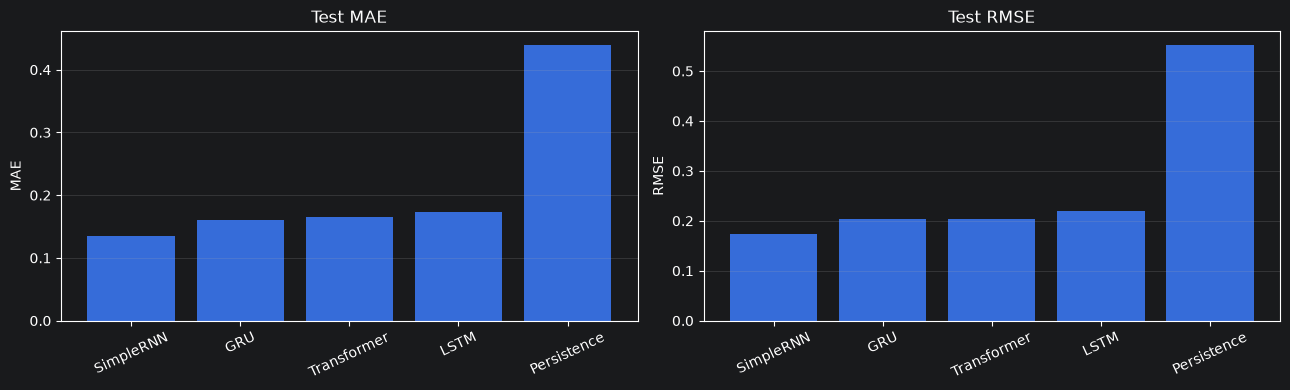

In [29]:
model_names = [row["Model"] for row in results]
mae_values = [row["MAE"] for row in results]
rmse_values = [row["RMSE"] for row in results]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(model_names, mae_values)
axes[0].set_title("Test MAE")
axes[0].set_ylabel("MAE")
axes[1].bar(model_names, rmse_values)
axes[1].set_title("Test RMSE")
axes[1].set_ylabel("RMSE")
for ax in axes:
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### Error by forecast horizon

The following plot reports MAE separately for each of the 12 future steps. It can reveal whether a model performs well near the forecast origin but degrades at longer horizons.

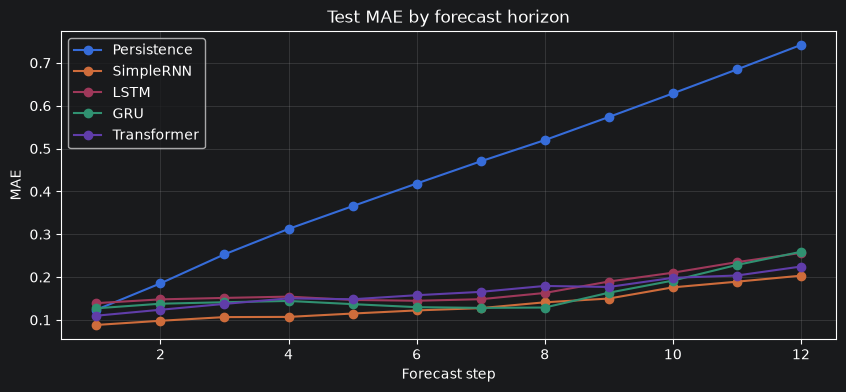

In [30]:
plt.figure(figsize=(10, 4))
for model_name, prediction in predictions_original.items():
    step_mae = np.mean(np.abs(y_test_original - prediction), axis=0)
    plt.plot(np.arange(1, HORIZON + 1), step_mae, marker="o", label=model_name)
plt.xlabel("Forecast step")
plt.ylabel("MAE")
plt.title("Test MAE by forecast horizon")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 20. Visualize forecast examples

A metric summarizes many forecasts but does not show their temporal behavior. Inspect individual forecast windows to see whether the model follows the trend and oscillations, oversmooths peaks, or misses a phase change.

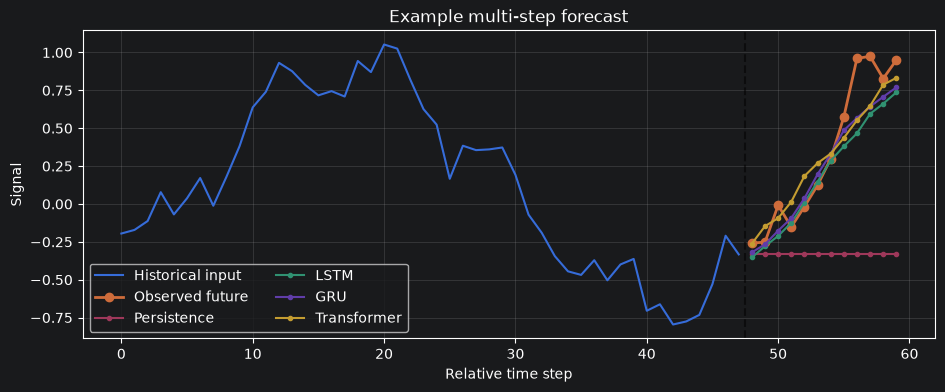

In [31]:
example_test_index = min(10, len(X_test) - 1)
input_values = X_test[example_test_index, :, 0] * train_std + train_mean
true_future = y_test_original[example_test_index]

plt.figure(figsize=(11, 4))
plt.plot(np.arange(SEQ_LEN), input_values, label="Historical input")
future_axis = np.arange(SEQ_LEN, SEQ_LEN + HORIZON)
plt.plot(future_axis, true_future, marker="o", linewidth=2, label="Observed future")
for model_name in ["Persistence", "LSTM", "GRU", "Transformer"]:
    if model_name in predictions_original:
        plt.plot(future_axis, predictions_original[model_name][example_test_index], marker=".", label=model_name)
plt.axvline(SEQ_LEN - 0.5, color="black", linestyle="--", alpha=0.5)
plt.title("Example multi-step forecast")
plt.xlabel("Relative time step")
plt.ylabel("Signal")
plt.legend(ncol=2)
plt.grid(alpha=0.25)
plt.show()

### Residual analysis

For each forecast, the residual is:

$$
e_{i,h} = y_{i,h} - \hat{y}_{i,h}
$$

Residuals should be inspected for systematic patterns. A non-zero mean, trend, changing variance, or strong temporal structure can indicate that the model is missing information or is poorly calibrated for some regions of the signal.

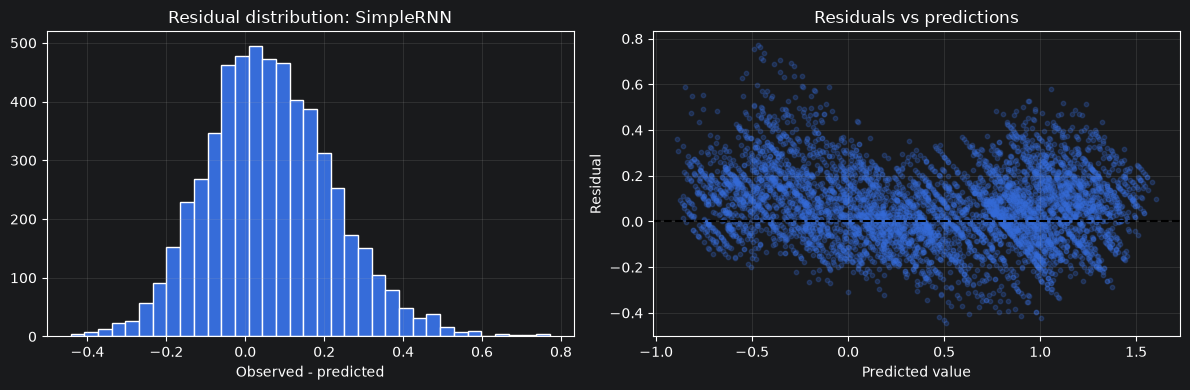

In [32]:
best_model_name = selected_model_name
best_residuals = y_test_original - predictions_original[best_model_name]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(best_residuals.reshape(-1), bins=35, edgecolor="white")
axes[0].set_title(f"Residual distribution: {best_model_name}")
axes[0].set_xlabel("Observed - predicted")
axes[1].scatter(
    predictions_original[best_model_name].reshape(-1),
    best_residuals.reshape(-1),
    alpha=0.25,
    s=10,
)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_title("Residuals vs predictions")
axes[1].set_xlabel("Predicted value")
axes[1].set_ylabel("Residual")
for ax in axes:
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 21. Important design choices and common pitfalls

1. **Random splitting of overlapping windows:** can create severe temporal leakage. Split the raw timeline first, then assign windows by their target period.
2. **Scaling before splitting:** leaks information from validation/test periods into preprocessing. Fit scalers on training data only.
3. **Ignoring the forecast horizon:** a model can perform well at step 1 and poorly at step 12. Report horizon-wise error.
4. **Comparing unequal protocols:** use consistent splits and evaluation rules for all candidate models.
5. **Assuming Transformers are always better:** attention can model relationships across positions, but it adds computation and may need more data.
6. **Using a causal mask by habit:** an encoder that sees only completed historical windows does not need a causal mask merely because the task is forecasting. Causal masking is necessary when a position must not access later positions in a target sequence.
7. **Treating a synthetic benchmark as clinical evidence:** artificial data are useful for controlled learning, not for claims about real patients or devices.

For clinical or longitudinal datasets, split at the patient level and, where appropriate, at the site or time level. Multiple observations from the same person must not be allowed to leak across training and test partitions.

## 22. Saving and loading a trained model

Keras recommends the `.keras` format for saving a complete model. Because this notebook defines custom layers, the custom classes must be available when the model is loaded, or be registered for serialization in a reusable project.

The following cell is optional. Run it after successful training if you want to save the Transformer model.

In [33]:
# Optional: save the trained Transformer model.
# The custom layer classes above are defined in this notebook and must be available when loading.
MODEL_PATH = "transformer_time_series_forecaster.keras"
transformer_model.save(MODEL_PATH)
print("Saved:", MODEL_PATH)

# To reload in this notebook session:
# restored_model = keras.models.load_model(
#     MODEL_PATH,
#     custom_objects={
#         "AddSinusoidalPositionEncoding": AddSinusoidalPositionEncoding,
#         "TransformerEncoderBlock": TransformerEncoderBlock,
#     },
# )

Saved: transformer_time_series_forecaster.keras


## 23. Key takeaways

- Sequential models use ordered context; the tensor convention is `(batch, time, features)`.
- Simple RNNs update a hidden state recurrently and can struggle with long dependencies because gradients may vanish or explode.
- LSTM and GRU gates provide learnable control over information flow; neither is universally best.
- Attention builds context by comparing queries with keys and aggregating values.
- Multi-head attention learns several attention projections in parallel.
- A Transformer needs positional information because standard self-attention alone does not represent sequence order.
- RNNs process steps recurrently; Transformer attention can process positions in parallel but full attention scales quadratically with sequence length.
- Time-series splits and preprocessing must respect chronology to avoid leakage.
- A simple persistence baseline and horizon-wise error analysis are essential for judging forecasting models.

## 24. Exercises

1. Change `SEQ_LEN` from 48 to 96. How does the amount of training data change, and how does the forecast performance change?
2. Change `HORIZON` from 12 to 24. Which architecture shows the largest increase in test error?
3. Replace the synthetic signal with a trend-plus-seasonality signal that has a sudden level shift. Which model adapts most effectively?
4. Add a second input feature (for example, a noisy version of one seasonal component). Update `N_FEATURES`, window construction, and model input shapes.
5. Build a stacked LSTM with `return_sequences=True` on the first layer and compare its parameter count and validation error with the single-layer model.
6. Add a second Transformer encoder block. Does the increase in parameters improve test performance?
7. Try a learned positional embedding instead of sinusoidal encoding.
8. Compare a direct multi-horizon model with an autoregressive one-step model. Discuss error accumulation.
9. Repeat the comparison with at least three random seeds and report mean and standard deviation of test MAE.
10. For a biomedical longitudinal dataset, propose a patient-level and temporal validation strategy that avoids leakage.

Do not choose hyperparameters by repeatedly checking the test set. Use validation data for model selection and reserve test data for the final evaluation.

## 25. Further reading and references

1. Hochreiter, S. & Schmidhuber, J. (1997). *Long Short-Term Memory*. Neural Computation, 9(8), 1735–1780. https://doi.org/10.1162/neco.1997.9.8.1735
2. Cho, K. et al. (2014). *Learning Phrase Representations using RNN Encoder–Decoder for Statistical Machine Translation*. https://arxiv.org/abs/1406.1078
3. Vaswani, A. et al. (2017). *Attention Is All You Need*. https://arxiv.org/abs/1706.03762
4. TensorFlow: *Neural machine translation with a Transformer and Keras*. https://www.tensorflow.org/text/tutorials/transformer
5. Keras: *Recurrent layers*. https://keras.io/api/layers/recurrent_layers/
6. Keras: *MultiHeadAttention layer*. https://keras.io/api/layers/attention_layers/multi_head_attention/
7. TensorFlow: *Time series forecasting tutorial*. https://www.tensorflow.org/tutorials/structured_data/time_series

---

**End of Notebook 10 — Sequential Deep Learning: RNN, LSTM, GRU and Transformers**